# 03 · Structural signal: how the papers are linked

This notebook studies the **structure** of the graph: its hyper-edges and the nodes they share. It assumes no particular coarsening algorithm. The aim is the opposite: to give empirical evidence about what information a coarsening algorithm should rely on.

It asks five questions:
1. Which nodes link papers, and through which relations?
2. What kinds of paper–paper relationship does the structure establish?
3. How do paper links change between three views: concept nodes only, document metadata nodes only, and both combined?
4. What structure does an individual node have at the finest level, and how does it change over time?
5. What must any coarser level represent to keep that structure usable?

The outcome, in section 9, is three sets of design rules for a coarsening algorithm:
- **(A)** which finest-level structural signals it should use;
- **(B)** which structural information it must carry over to coarser levels, so that super-nodes can themselves be coarsened;
- **(C)** which structural information it must leave out, so that coherence can be evaluated independently.

Where the evidence is descriptive rather than an outcome test, the rule is marked as a hypothesis, together with the test that would settle it.

**Vocabulary.**
- *Concept nodes:* method, task, problem, technique, component, dataset, metric. These are the node types that occur as members of the method-centred relations; section 1 shows this from the export's schema.
- *Document metadata nodes:* author, cited work, claim, future topic, article. These hang off the article.
- *Linking.* A node **links** papers *p* and *q* when it occurs in both, in an edge of each paper or in the provenance of each.
- *Hubs.* Nodes found in more than a given share of a snapshot's papers. 20% is used as the analysis's operating point, and section 2 shows the sensitivity.
- *Concept-relation hypergraph.* The six method-centred relations, with members restricted to concept nodes, hubs removed, and edges with fewer than two members dropped. It is the finest-level structure studied in sections 5–7.

**Design-time caveat.** Sections 1, 3, 4 and 8 look at citations, which serve as an evaluation ruler for coherence (`tkh/evaluate/coherence.py`). Any design choice motivated here must be judged on held-out evidence, not on the descriptive comparisons made in this notebook.

Reusable code is in `tkh/structure.py`, which is independent of the project's coarsening code. Unless stated otherwise, the analysis covers the whole collection (≤2026).

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import os, sys
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
from scipy.stats import spearmanr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from tkh.config import load_config
from tkh.io import load, snapshot, make_snapshots
from tkh import structure as st
from tkh.structure import CONCEPT_TYPES

pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
cfg = load_config(os.environ.get("TKH_CONFIG"))
tkh = load(cfg)
N = tkh.nodes; E = tkh.edges
ntype = N["type"].to_dict(); name = N["surface_form"].to_dict(); year = tkh.articles["year"].to_dict()
HUB = 0.2       # hub threshold: the project's default setting, used here only as an operating point (sensitivity: sections 2 and 7)
GROUPS = [15, 60, 240]   # group counts for section 7: the brief's top-level budget N_0 ≈ 15, then x4 refinements
META = ("author", "cited_work")      # the only metadata types that occur in more than one paper (section 1)
print(f"{len(tkh.articles)} papers, {len(N)} nodes, {len(E)} hyper-edges; python {sys.version.split()[0]}, matplotlib {matplotlib.__version__}")

52 papers, 5798 nodes, 1429 hyper-edges; python 3.12.11, matplotlib 3.11.2


## 1. Which nodes can link papers

Each paper contributes stars whose hub is either the article (presents, claims, authored_by, cites, proposes_future_work) or its presented method (the six concept relations). Most relations have one star per paper. `claims` and `evaluated_on` have many per paper. Papers can only be linked by nodes that occur in more than one paper. The tables count such nodes by type, and show how much of the export each relation covers.

In [2]:
share = st.sharing_by_type(tkh)
share

,kind,nodes,in >= 2 papers,share shared,max papers,paper pairs linked
type,,,,,,
task,concept,732,73,0.100,51,1275
method,concept,448,95,0.212,10,273
metric,concept,90,10,0.111,11,85
technique,concept,962,30,0.031,4,41
dataset,concept,259,24,0.093,4,27
component,concept,855,9,0.011,3,13
problem,concept,634,8,0.013,3,12
cited_work,metadata,580,122,0.210,13,316
author,metadata,318,42,0.132,4,38


In [3]:
roles = Counter((r, "hub" if i == 0 else "member", ntype[v]) for m, r in zip(E["members"], E["relation_type"]) for i, v in enumerate(m))
rel = pd.Series(roles).rename_axis(["relation", "position", "node type"]).to_frame("slots").reset_index()
display(rel.pivot_table(index=["relation", "position"], columns="node type", values="slots", fill_value=0))
cover = pd.Series({r: E.loc[E["relation_type"] == r, "article_id"].nunique() for r in sorted(E["relation_type"].unique())}, name="papers with this relation")
cover.to_frame().T

node type                      article  author  cited_work  claim  component  \
relation             position                                                  
addresses            hub           0.0     0.0         0.0    0.0        0.0   
                     member        0.0     0.0         0.0    0.0        0.0   
authored_by          hub          51.0     0.0         0.0    0.0        0.0   
                     member        0.0   375.0         0.0    0.0        0.0   
cites                hub          37.0     0.0         0.0    0.0        0.0   
                     member        0.0     0.0       878.0    0.0        0.0   
claims               hub         690.0     0.0         0.0    0.0        0.0   
                     member        0.0     0.0         0.0  690.0        0.0   
evaluated_on         hub           0.0     0.0         0.0    0.0        0.0   
                     member        0.0     0.0         0.0    0.0        0.0   
extends              hub           0.0     0.0         0.0    0.0        0.0   
                     member        0.0     0.0         0.0    0.0        0.0   
presents             hub          52.0     0.0         0.0    0.0        0.0   
                     member        0.0     0.0         0.0    0.0        0.0   
proposes_future_work hub          45.0     0.0         0.0    0.0        0.0   
                     member        0.0     0.0         0.0    0.0        0.0   
solves               hub           0.0     0.0         0.0    0.0        0.0   
                     member        0.0     0.0         0.0    0.0        0.0   
uses_component       hub           0.0     0.0         0.0    0.0        0.0   
                     member        0.0     0.0         0.0    0.0      866.0   
uses_technique       hub           0.0     0.0         0.0    0.0        0.0   
                     member        0.0     0.0         0.0    0.0        0.0   

node type                      dataset  future_topic  method  metric  problem  \
relation             position                                                   
addresses            hub           0.0           0.0    51.0     0.0      0.0   
                     member        0.0           0.0     0.0     0.0      0.0   
authored_by          hub           0.0           0.0     0.0     0.0      0.0   
                     member        0.0           0.0     0.0     0.0      0.0   
cites                hub           0.0           0.0     0.0     0.0      0.0   
                     member        0.0           0.0     0.0     0.0      0.0   
claims               hub           0.0           0.0     0.0     0.0      0.0   
                     member        0.0           0.0   478.0     0.0      0.0   
evaluated_on         hub           0.0           0.0   301.0     0.0      0.0   
                     member      512.0           0.0     0.0   259.0      0.0   
extends              hub           0.0           0.0    50.0     0.0      0.0   
                     member        0.0           0.0   579.0     0.0      0.0   
presents             hub           0.0           0.0     0.0     0.0      0.0   
                     member        0.0           0.0    52.0     0.0      0.0   
proposes_future_work hub           0.0           0.0     0.0     0.0      0.0   
                     member        0.0         178.0     0.0     0.0      0.0   
solves               hub           0.0           0.0    51.0     0.0      0.0   
                     member        0.0           0.0     0.0     0.0    644.0   
uses_component       hub           0.0           0.0    50.0     0.0      0.0   
                     member        0.0           0.0     0.0     0.0      0.0   
uses_technique       hub           0.0           0.0    51.0     0.0      0.0   
                     member        0.0           0.0     0.0     0.0      0.0   

node type                       task  technique  
relation             position                    
addresses            hub         0

,addresses,authored_by,cites,claims,evaluated_on,extends,presents,proposes_future_work,solves,uses_component,uses_technique
papers with this relation,51,51,37,52,36,50,52,45,51,50,51


In [4]:
schema, ok = st.schema_check(tkh)
print("method-centred relations hold exactly the seven concept types as members:", ok)
schema

method-centred relations hold exactly the seven concept types as members: True


,hub types,member types
addresses,method,task
authored_by,article,author
cites,article,cited_work
claims,article,"claim, method"
evaluated_on,method,"dataset, metric"
extends,method,method
presents,article,method
proposes_future_work,article,future_topic
solves,method,problem
uses_component,method,component


What the tables show:
- **The concept/metadata split follows the schema** (the check above).
  - The six relations whose hub is the presented method (addresses, solves, extends, uses_component, uses_technique, evaluated_on) have only the seven concept types as members.
  - Every other relation is centred on the article and holds the metadata types. Claims are the exception: they also hold methods.
  - Each of the six relations also has essentially one member type: tasks for `addresses`, problems for `solves`, and so on; `evaluated_on` holds datasets and metrics.
  - So a relation-typed weighting is nearly a type-typed weighting.
  - Two groups of different non-method types can only be linked through a method. The exception is datasets and metrics, which `evaluated_on` links directly.
- **Three metadata types never link papers.** Every claim, future topic and article node occurs in exactly one paper. They describe their paper but do not connect it.
- **Two metadata types do link papers.** Shared **cited works** (bibliographic coupling) and shared **authors** (co-authorship).
  - *Citation coverage is incomplete.* Only 37 of the 52 papers have a `cites` edge, including none for some heavily built-on papers. Part of the metadata view's sparseness is therefore an extraction gap, and the citation-based ruler (E1a) can only ever score pairs among those 37 papers.
- **Concept types link papers very unevenly.**
  - Tasks link the most pairs, but through a few generic tasks: one occurs in 51 of the 52 papers.
  - Methods are the most often shared type, mostly through `extends`.
  - Metrics and datasets link papers as shared benchmarks.
  - Components and problems almost never occur in two papers.
- **One paper has no concept-relation edges at all** (section 4), so the concept structure cannot place it.
- **Claims edges also hold methods**, in most cases the hub paper's own presented method (checked in section 8).

## 2. Shared nodes, hubs and specificity

A node in two papers says more about those two papers than a node in 51 does. The table shows how many paper pairs the concept view links when nodes above a given paper share are dropped. The chart shows which nodes link the most papers.

In [5]:
st.hub_sensitivity(tkh, CONCEPT_TYPES)

,papers,linked pairs,density,components,largest component,isolated papers,median partners per paper
drop nodes in more than,,,,,,,
nothing,52,1275,0.962,2,51,1,50.0
50% of papers,52,638,0.481,2,51,1,26.5
30% of papers,52,562,0.424,2,51,1,22.5
20% of papers,52,442,0.333,2,51,1,17.5
10% of papers,52,316,0.238,2,51,1,12.0
5% of papers,52,117,0.088,3,50,2,4.0


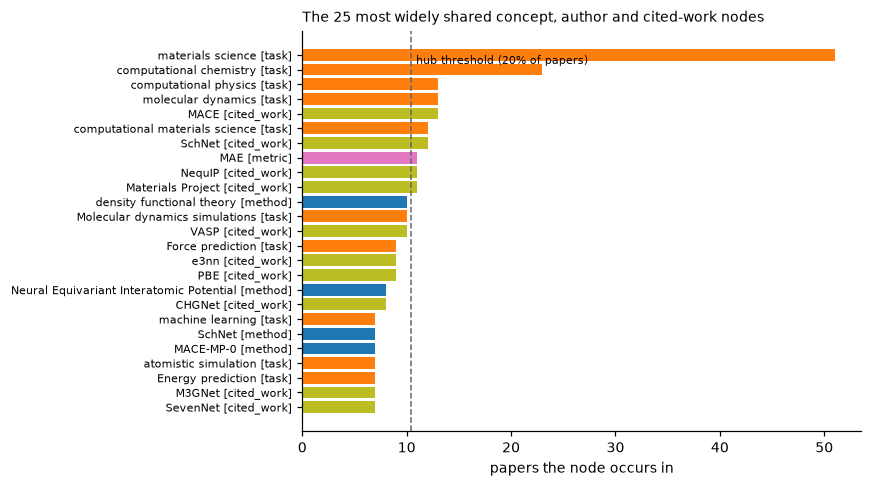

In [6]:
papers = st.node_papers(tkh)
top = sorted((v for v in papers if ntype[v] in CONCEPT_TYPES + META), key=lambda v: -len(papers[v]))[:25]
fig, ax = plt.subplots(figsize=(8, 4.5))
cols = {t: plt.get_cmap("tab10")(i) for i, t in enumerate(CONCEPT_TYPES + META)}
ax.barh(range(len(top))[::-1], [len(papers[v]) for v in top], color=[cols[ntype[v]] for v in top])
ax.set_yticks(range(len(top))[::-1], [f"{name[v][:40]} [{ntype[v]}]" for v in top], fontsize=7)
ax.axvline(HUB * len(tkh.articles), color="0.4", ls="--", lw=1)
ax.text(HUB * len(tkh.articles) + 0.5, len(top) - 1, "hub threshold (20% of papers)", fontsize=7, va="top")
ax.set_xlabel("papers the node occurs in")
ax.set_title("The 25 most widely shared concept, author and cited-work nodes", fontsize=9, loc="left")
fig.tight_layout()

**Hubs dominate the unweighted concept view.**
- *With hubs.* Almost every pair of papers is linked, mostly through generic domain terms: 'materials science', 'computational chemistry', 'MAE'.
- *Without the most extreme ones.* Dropping only nodes in more than half of the papers already halves the number of linked pairs.
- *The gap above the threshold.* The two most widespread terms are far above all others, but below them the paper counts fall in a long tail with no gap. The 20% threshold cuts inside that tail, so it is a design choice, not a property of the data.
- *Below 20%,* a third of the pairs stay linked and only one paper is left isolated.

## 3. Typed relationships between papers

A shared concept node is typed by the relation it has in each of the two papers. One combination is directed. When one paper's `extends` edge contains the method another paper `presents`, the first builds on the second. This is a **lineage** link, oriented by these roles. Lineage links between papers of the same year are flagged, because the years cannot confirm the order. The other combinations are symmetric. For example, `evaluated_on ~ evaluated_on` is a shared benchmark, and `addresses ~ addresses` is a shared task. Hubs are excluded.

The metadata view adds three more relationship types:
- **co-authorship**, a shared author;
- **bibliographic coupling**, a shared cited work;
- **direct citation**, where a paper cites a work whose name is another paper's presented method.

In [7]:
tl = st.typed_links(tkh, max_paper_share=HUB)
spec = tl[~tl["hub"]]
typed = (spec.groupby("link")
         .apply(lambda g: pd.Series({"paper pairs": len(set(zip(g["earlier"], g["later"]))), "linking nodes": g["node"].nunique(),
                                     "median papers per node": g["papers of node"].median(),
                                     "same-year pairs": len(set(zip(g.loc[g["same year"], "earlier"], g.loc[g["same year"], "later"]))),
                                     "example node": name[g["node"].value_counts().index[0]][:40]}))
         .sort_values("paper pairs", ascending=False))
coauthor = st.pair_matrix(tkh, ("author",))[1]
coupling = st.pair_matrix(tkh, ("cited_work",))[1]
direct = st.citation_name_pairs(tkh)
meta_rows = pd.DataFrame({"paper pairs": [len(coauthor), len(coupling), len({tuple(sorted(p, key=str)) for p in direct})],
                          "linking nodes": [len({v for vs in coauthor.values() for v in vs}), len({v for vs in coupling.values() for v in vs}), np.nan]},
                         index=["co-authorship (shared author)", "bibliographic coupling (shared cited work)",
                                "direct citation (cited work named like the other paper's method)"])
display(typed)
meta_rows

,paper pairs,linking nodes,median papers per node,same-year pairs,example node
link,,,,,
extends ~ extends,241,87,5.0,38,density functional theory
addresses ~ addresses,205,68,5.0,28,Molecular dynamics simulations
evaluated_on ~ evaluated_on,49,33,3.5,12,Energy MAE
extends -> presents (lineage),49,16,5.0,3,Neural Equivariant Interatomic Potential
uses_technique ~ uses_technique,41,30,3.0,6,Gradient clipping
uses_component ~ uses_component,13,9,2.0,1,Interaction block
solves ~ solves,12,8,2.5,0,Thermodynamic stability prediction
claims ~ extends,8,3,4.5,0,NequIP


,paper pairs,linking nodes
co-authorship (shared author),38,42.0
bibliographic coupling (shared cited work),316,122.0
direct citation (cited work named like the other paper's method),90,NaN


In [8]:
lineage = st.lineage_pairs(tkh)
lin = pd.DataFrame(lineage, columns=["later", "earlier"])
lin["gap (years)"] = [year[a] - year[b] for a, b in lineage]
direct_set = set(direct)
lin["also cited by name"] = [(a, b) in direct_set for a, b in lineage]
print(f"{len(lineage)} lineage pairs (extending paper -> presenting paper); gap >= 0 for all: {all(lin['gap (years)'] >= 0)} "
      f"({(lin['gap (years)'] == 0).sum()} same-year); {lin['also cited by name'].sum()} are also direct citations")
built_on = Counter(b for _, b in lineage)
pd.DataFrame([{"paper": b, "year": year[b], "title": tkh.articles.at[b, 'title'][:70], "built on by": c}
              for b, c in built_on.most_common(8)]).set_index("paper")

49 lineage pairs (extending paper -> presenting paper); gap >= 0 for all: True (3 same-year); 30 are also direct citations


,year,title,built on by
paper,,,
5388,2021,E(3)-Equivariant Graph Neural Networks for Data-Efficient and Accurate,7
4167,2017,SchNet: A continuous-filter convolutional neural network for modeling,6
5380,2023,MACE: Higher Order Equivariant Message Passing Neural Networks for Fas,6
4166,2017,Neural Message Passing for Quantum Chemistry,5
5451,2016,Machine-learning based interatomic potential for amorphous carbon,4
5396,2018,Crystal Graph Convolutional Neural Networks for an Accurate and Interp,4
5444,2024,EQUIFORMERV2: IMPROVED EQUIVARIANT TRANSFORMER FOR SCALING TO HIGHER-D,4
5439,2024,Scalable Parallel Algorithm for Graph Neural Network Interatomic Poten,3


**The typed view separates what the counts mix together.**
- *Most cross-paper links are shared-use links.* Two papers extend the same method, address the same task, or are evaluated on the same benchmark. Some come from generic methods that survive the hub threshold, e.g. 'density functional theory' in `extends`.
- *Lineage is the most informative kind of link, but it does not come from rare nodes.* It is directed and, wherever the years differ, points to an earlier paper. Its linking nodes are popular methods (NequIP, SchNet, MACE …) that many later papers build on.
- *Lineage overlaps the citation signal.* Most lineage pairs are also direct citations: a paper that extends a method usually cites it. Section 8 shows what this means for evaluation.
- *Claims add almost nothing.* The `claims ~ extends` rows are a method that one paper makes claims about and another extends. They are rare, because claims edges almost always hold the paper's own method.

## 4. Three views of the paper graph: concept, metadata, combined

Each view is a weighted paper × paper matrix. Each shared node adds an IDF weight, log(N / papers of the node). The views are:
- **concept view:** concept nodes, hubs removed;
- **metadata view:** authors and cited works, the only metadata that links papers;
- **combined view:** the concept view plus the full metadata view. The hub filter applies to concept nodes only, as in the concept view.

**How agreement is measured.** Over *all* paper pairs, using two statistics:
- the rank correlation of the weights;
- the odds ratio of "linked in one view" against "linked in the other".

Both are compared with a null that permutes one view's paper labels within publication years. A correlation restricted to pairs linked in at least one view would be biased strongly negative by construction, so it is not used.

In [9]:
C_mat = st.pair_matrix(tkh, CONCEPT_TYPES, max_paper_share=HUB)[0]
M_mat = st.pair_matrix(tkh, META)[0]
views = {"concept": C_mat, "metadata": M_mat, "combined": C_mat + M_mat,
         "authors only": st.pair_matrix(tkh, ("author",))[0], "cited works only": st.pair_matrix(tkh, ("cited_work",))[0]}
iso = [a for a in C_mat.index if C_mat.loc[a].sum() == 0]
print("papers isolated in the concept view:", [(a, tkh.articles.at[a, 'title'][:50],
      int(((E['article_id'] == a) & E['relation_type'].isin(st.CONCEPT_RELATIONS)).sum()), "concept-relation edges") for a in iso])
pd.DataFrame({k: st.link_summary(M) for k, M in views.items()}).T

papers isolated in the concept view: [(5405, 'Universal Machine Learning Kohn-Sham Hamiltonian f', 0, 'concept-relation edges')]


,papers,linked pairs,density,components,largest component,isolated papers,median partners per paper
concept,52.0,442.0,0.333,2.0,51.0,1.0,17.5
metadata,52.0,344.0,0.259,6.0,47.0,5.0,14.0
combined,52.0,590.0,0.445,2.0,51.0,1.0,24.5
authors only,52.0,38.0,0.029,24.0,11.0,16.0,1.0
cited works only,52.0,316.0,0.238,16.0,37.0,15.0,14.0


In [10]:
strata = [year[a] for a in C_mat.index]
agree = pd.DataFrame({f"concept vs {b}": st.matrix_agreement(C_mat, views[b], n_perm=999, strata=strata)
                      for b in ["metadata", "authors only", "cited works only"]}).T
agree[["pairs in A", "pairs in B", "pairs in both", "Jaccard", "spearman", "spearman null mean", "spearman p",
       "odds ratio", "odds ratio null mean", "odds ratio p", "P(B | A)", "P(B | not A)"]]

,pairs in A,pairs in B,pairs in both,Jaccard,spearman,spearman null mean,spearman p,odds ratio,odds ratio null mean,odds ratio p,P(B | A),P(B | not A)
concept vs metadata,442.0,344.0,196.0,0.332,0.362,0.105,0.001,3.954,1.574,0.001,0.443,0.167
concept vs authors only,442.0,38.0,20.0,0.043,0.094,0.022,0.014,2.273,1.359,0.057,0.045,0.020
concept vs cited works only,442.0,316.0,184.0,0.321,0.355,0.106,0.001,4.053,1.603,0.001,0.416,0.149


Text(0.1, 0.98, 'Papers ordered by publication year')

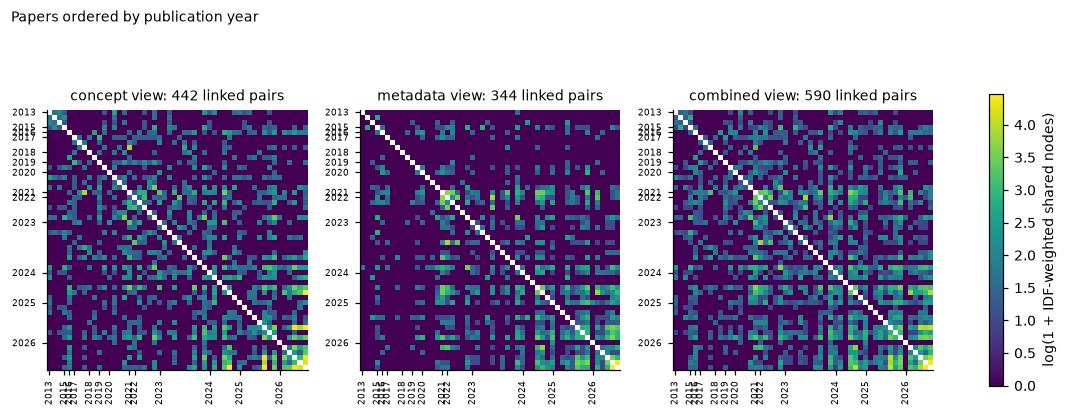

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, k in zip(axes, ["concept", "metadata", "combined"]):
    M = views[k].values.copy()
    np.fill_diagonal(M, np.nan)
    im = ax.imshow(np.log1p(M), cmap="viridis")
    ax.set_title(f"{k} view: {st.link_summary(views[k])['linked pairs']} linked pairs", fontsize=9)
    ticks = [i for i, a in enumerate(views[k].index) if i == 0 or year[a] != year[views[k].index[i - 1]]]
    ax.set_xticks(ticks, [year[views[k].index[i]] for i in ticks], rotation=90, fontsize=6)
    ax.set_yticks(ticks, [year[views[k].index[i]] for i in ticks], fontsize=6)
fig.colorbar(im, ax=axes, shrink=0.8, label="log(1 + IDF-weighted shared nodes)")
fig.suptitle("Papers ordered by publication year", fontsize=9, x=0.1, ha="left")

In [12]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import adjusted_rand_score

def paper_groups(M, k):
    S = M.values / (M.values.max() or 1)
    D = 1 - S; np.fill_diagonal(D, 0)
    return fcluster(linkage(squareform(D, checks=False), "average"), k, criterion="maxclust")

rows = []
for k in (4, 6, 8, 10, 12):
    g = {v: paper_groups(views[v], k) for v in ["concept", "metadata", "combined"]}
    rows.append({"k": k, "ARI concept–metadata": adjusted_rand_score(g["concept"], g["metadata"]),
                 "ARI concept–combined": adjusted_rand_score(g["concept"], g["combined"]),
                 "ARI metadata–combined": adjusted_rand_score(g["metadata"], g["combined"]),
                 **{f"groups obtained ({v})": int(len(set(g[v]))) for v in g},
                 **{f"largest group ({v})": int(np.bincount(g[v]).max()) for v in g}})
pd.DataFrame(rows).set_index("k")

,ARI concept–metadata,ARI concept–combined,ARI metadata–combined,groups obtained (concept),groups obtained (metadata),groups obtained (combined),largest group (concept),largest group (metadata),largest group (combined)
k,,,,,,,,,
4,0.000,0.639,0.000,4,1,4,49,52,49
6,0.474,0.549,0.433,6,6,6,46,47,42
8,0.072,0.170,0.472,8,8,8,23,44,37
10,0.127,0.201,0.443,10,10,10,23,42,31
12,0.196,0.396,0.341,12,12,12,19,40,25


**What changes between the views:**
- **Concept view.** It links a third of all pairs and every paper but one. The exception has no concept-relation edges in the export. The links are broad: shared methods and benchmarks connect papers across years.
- **Metadata view.** It is a little sparser and fragmented. Several papers share no author or cited work with any other paper, and all of them are among the 15 papers with no extracted citations. Its links come almost entirely from cited works; co-authorship links only a few dozen pairs.
- **The views are positively associated, far above the year-matched null.**
  - Papers linked in the concept view are much more likely to be linked in the metadata view too.
  - Their weights are rank-correlated over all pairs.
  - The association comes from cited works. Co-authorship is only weakly associated with the concept view.
  - The two views are therefore related measurements of "these papers work on related things", not independent ones. A citation-based ruler is meaningful *because* it agrees with structure to some degree. It is independent only in the sense that it is kept out of the clustering (section 8).
- **Combined view.** It is mostly the union of the two. Neither view adds a negligible number of pairs.
- **Paper groupings** cut from the views (average linkage) agree or disagree depending on the number of groups. All of them degenerate into one large group plus near-singletons at small k. At k = 4 the metadata view does not even reach four groups. Such groupings support no conclusion about which view "groups papers better".

## 5. From papers to nodes: what structure a single node has

A coarsening of this graph merges **nodes**, not papers. At the finest level a concept node's structure consists of:
- the edges of its own paper's stars, which give its role (relation) and the other members of that star;
- if it occurs in several papers, the stars of those papers too.

Three quantities follow:
- how many nodes bridge papers within each relation;
- how much of the concept-relation hypergraph each relation represents under different edge weightings;
- how far the structure connects nodes once hubs are removed.

In [13]:
st.relation_bridges(tkh, max_paper_share=HUB)

,edges,member slots,distinct members,"bridge members (in 2+ papers within the relation, not hubs)",share of members that bridge,paper pairs linked within the relation
relation,,,,,,
addresses,51,988,732,68,0.093,205
solves,51,644,634,8,0.013,12
extends,50,579,412,87,0.211,241
uses_component,50,866,855,9,0.011,13
uses_technique,51,1001,962,30,0.031,41
evaluated_on,301,771,349,33,0.095,49


In [14]:
st.relation_weight(tkh, max_paper_share=HUB)

,edges,share: edges,share: member slots,share: inverse size,share: clique pairs,median arity,top-3 papers' share of the edges
relation,,,,,,,
evaluated_on,301,0.543,0.199,0.853,0.051,3.0,0.322
addresses,51,0.092,0.176,0.032,0.250,12.0,0.059
solves,51,0.092,0.132,0.035,0.127,10.0,0.059
uses_technique,51,0.092,0.200,0.021,0.278,16.0,0.059
extends,50,0.090,0.119,0.037,0.093,11.5,0.060
uses_component,50,0.090,0.174,0.021,0.201,17.0,0.060


In [15]:
rows = []
for s in make_snapshots(tkh, cfg.cutoffs):
    sizes, spans, hubset = st.concept_components(tkh, s, max_paper_share=HUB)
    pap = st.node_papers(tkh, s)
    concept = [v for v in s.node_ids if ntype[v] in CONCEPT_TYPES]
    rows.append({"snapshot": s.cutoff, "concept nodes": len(concept), "hubs (excluded)": len(hubset),
                 "single-paper concept nodes": np.mean([len(pap.get(v, ())) == 1 for v in concept]),
                 "components": len(sizes), "largest component (share of non-hub nodes)": sizes[0] / sum(sizes),
                 "papers spanned by the largest": spans[0], "papers in snapshot": len(s.articles)})
pd.DataFrame(rows).set_index("snapshot")

,concept nodes,hubs (excluded),single-paper concept nodes,components,largest component (share of non-hub nodes),papers spanned by the largest,papers in snapshot
snapshot,,,,,,,
2020,1018,5,0.964,2,0.981,15,16
2022,1464,8,0.949,6,0.993,22,22
2024,2829,7,0.948,2,1.000,37,38
2026,3980,6,0.937,2,1.000,51,52


**What this means for a coarsening algorithm:**
- **Most concept nodes have only within-paper structure.** For most of them, the only edges are their own paper's stars. Their structural neighbours are the other tasks, techniques or components of the *same paper and relation*. Structure alone can only group them into paper-and-relation bundles: all tasks of one paper, all techniques of another.
- **The cross-paper structure is carried by a small set of bridges,** mostly in `extends` (shared methods), `addresses` (shared tasks) and `evaluated_on` (shared benchmarks). Components and problems almost never bridge. Yet these few bridges connect nearly all non-hub concept nodes into one component. Connectivity therefore does not delimit groups: grouping must come from how *strongly* nodes are connected, not from whether they are.
- **The choice of edge weighting decides which relation dominates.** `evaluated_on` is about half of the edges, but they are small: a method with one dataset and metric.
  - *Inverse-size weighting* (1/(|e| − 1)), a common normalisation, gives `evaluated_on` most of the total weight.
  - *Counting member slots* gives it a fifth.
  - *A pairwise projection* (clique pairs) gives it almost none, and hands the large `addresses` and `uses_technique` stars most of the weight.
  - A few papers with many benchmark entries contribute a large share of the `evaluated_on` edges.
  - Whatever weighting an algorithm uses, it implicitly chooses which relation drives the grouping. That should be a deliberate, tested choice (section 9).

## 6. How the structure changes over time

A coarsening of an evolving graph works on each snapshot. Two things change between snapshots: new papers attach to old ones through typed links, and the hub set itself changes. A node that stops being a hub *re-enters* the concept-relation edges, and one that becomes a hub leaves them.

In [16]:
cut = sorted(cfg.cutoffs)
period = lambda y: next(c for c in cut if y <= c)
rows = []
for c0, c1 in zip(cut, cut[1:]):
    s1 = snapshot(tkh, c1)
    t1 = st.typed_links(tkh, s1, max_paper_share=HUB)
    t1 = t1[~t1["hub"] | (t1["link"] == "extends -> presents (lineage)")]   # lineage is specific even through a hub method
    new = {a for a in s1.articles if year[a] > c0}
    newold = t1[t1["earlier"].map(lambda a: a not in new) & t1["later"].isin(new) | t1["earlier"].isin(new) & ~t1["later"].isin(new)]
    cnt = newold.groupby("link").apply(lambda g: len(set(zip(g["earlier"], g["later"]))))
    rows.append({"transition": f"{c0}→{c1}", "new papers": len(new), **cnt.to_dict()})
attach = pd.DataFrame(rows).set_index("transition").fillna(0).astype(int)
attach

,new papers,addresses ~ addresses,evaluated_on ~ evaluated_on,extends -> presents (lineage),extends ~ extends,solves ~ solves,uses_component ~ uses_component,uses_technique ~ uses_technique,claims ~ extends
transition,,,,,,,,,
2020→2022,6,9,1,8,11,1,2,2,0
2022→2024,16,31,11,11,63,2,5,11,6
2024→2026,14,99,19,16,65,5,2,14,1


In [17]:
hub_sets = {c: st.concept_components(tkh, snapshot(tkh, c), max_paper_share=HUB)[2] for c in cut}
rows = []
for c0, c1 in zip(cut, cut[1:]):
    left, joined = hub_sets[c0] - hub_sets[c1], hub_sets[c1] - hub_sets[c0]
    s0 = snapshot(tkh, c0)
    reduced = lambda m, hs: tuple(v for v in dict.fromkeys(m) if ntype[v] in CONCEPT_TYPES and v not in hs)
    touched = 0
    for m, r in zip(s0.edges["members"], s0.edges["relation_type"]):   # edges that already existed at c0
        if r in st.CONCEPT_RELATIONS:
            a, b = reduced(m, hub_sets[c0]), reduced(m, hub_sets[c1])
            touched += a != b and (len(a) >= 2 or len(b) >= 2)
    rows.append({"transition": f"{c0}→{c1}", "stop being hubs": "; ".join(sorted(name[v] for v in left)) or "—",
                 "become hubs": "; ".join(sorted(name[v] for v in joined)) or "—",
                 "existing concept-relation edges whose membership changes": touched})
pd.DataFrame(rows).set_index("transition")

,stop being hubs,become hubs,existing concept-relation edges whose membership changes
transition,,,
2020→2022,—,MAE; Message Passing Neural Network; computational chemistry,20
2022→2024,Message Passing Neural Network; machine learning,molecular dynamics,21
2024→2026,density functional theory,—,8


**Reading:**
- **New papers attach to the old ones mainly through shared-use links**: shared methods, tasks and benchmarks. Lineage links into the past grow with every step. Lineage is counted even when the built-on method is a hub, as 'Message Passing Neural Network' is at 2022.
- **The hub set churns.**
  - 'density functional theory' and 'machine learning' are hubs from 2020 and drop out later.
  - 'Message Passing Neural Network' is a hub only at 2022.
  - 'MAE' and 'computational chemistry' join at 2022, and 'molecular dynamics' at 2024.
- **Churn changes the hypergraph itself, not only its size.** Existing edges that contain a node entering or leaving the hub set gain or lose that member (last column). Any temporal smoothing has to account for this: the input hypergraph itself changes between snapshots. A hub list fixed across snapshots, or a soft down-weighting by paper share instead of a hard threshold, would remove this source of change (section 9).

## 7. What any coarser level has to represent

At a coarser level the items are groups of nodes. To coarsen *those* groups in turn, an algorithm needs some structural summary of how groups are connected. To keep this algorithm-independent, the concept-relation hypergraph is collapsed onto **reference partitions** that encode no clustering method. Each is built at 15 groups (the brief's top-level budget, N_0 ≈ 10–15) and at 60 and 240 groups (×4 refinements), with 20 random seeds:
- **random:** uniformly random groups of equal size;
- **paper-preserving:** each node goes to its earliest paper. At 15 groups every group is a set of whole papers; at 60 and 240 every group is part of one paper.
- **type-preserving:** groups never mix node types.

Group-pair affinities are computed twice: with every edge weighted equally, and with the inverse-size weighting of section 5. Presence and endpoint counts are compared under both.

Every fine edge is mapped to the groups it touches (λ = number of distinct groups). The questions are:
- **Internal edges:** how many edges fall entirely inside one group, so that they no longer link groups at all.
- **Multi-way edges:** how many linking edges stay multi-way (λ ≥ 3), and how many pairs a pairwise summary would create for each. A pairwise summary would split exactly these edges.
- **Density:** how many group pairs share an edge, which shows whether edge *presence* still discriminates between pairs.
- **Presence vs counts:** whether a group-pair affinity that uses endpoint counts ranks pairs differently from one that uses presence only.
- **Paper coverage:** how many papers a group touches, the coarse-level analogue of hubness.

In [18]:
items, Binc, edge_paper, edge_rel = st.concept_incidence(tkh, snapshot(tkh, max(cfg.cutoffs)), max_paper_share=HUB)
weights = {"uniform": np.ones(Binc.shape[1]), "inverse-size": 1 / (Binc.sum(axis=0) - 1)}   # two candidate edge weightings
pap26 = st.node_papers(tkh, snapshot(tkh, max(cfg.cutoffs)))
item_papers = [pap26[v] for v in items]
rows = []
for kind in ("random", "paper", "type"):
    for k in sorted(GROUPS, reverse=True):
        stats = [st.collapse_stats(st.reference_partition(kind, items, k, tkh, seed, snapshot(tkh, max(cfg.cutoffs))),
                                   Binc, item_papers=item_papers, n_papers=len(tkh.articles), affinity_weights=weights)
                 for seed in range(20)]
        d = pd.DataFrame(stats)
        rows.append({"partition": kind, "groups": k, **d.mean().drop(["groups", "Spearman(coverage, size)"]).to_dict()})
ref = pd.DataFrame(rows).set_index(["partition", "groups"])
print(f"{len(items)} non-hub concept nodes, {Binc.shape[1]} concept-relation edges; means over 20 seeds")
ref

3974 non-hub concept nodes, 554 concept-relation edges; means over 20 seeds


internal edges  multi-way among linking edges  \
partition groups                                                  
random    240          1.805e-04                          0.928   
          60           1.534e-03                          0.911   
          15           5.144e-03                          0.855   
paper     240          3.430e-02                          0.711   
          60           5.363e-01                          0.455   
          15           6.399e-01                          0.431   
type      240          9.025e-05                          0.932   
          60           4.513e-04                          0.928   
          15           2.617e-03                          0.787   

                  projection pairs per multi-way edge  \
partition groups                                        
random    240                                  87.762   
          60                                   64.538   
          15                                   25.465   
paper     240                                  17.303   
          60                                   11.414   
          15                                    8.417   
type      240                                  58.096   
          60                                   18.977   
          15                                    3.952   

                  group pairs sharing an edge  \
partition groups                                
random    240                           0.805   
          60                            1.000   
          15                            1.000   
paper     240                           0.116   
          60                            0.373   
          15                            0.976   
type      240                           0.263   
          60                            0.375   
          15                            0.362   

                  Spearman(presence, counts), uniform weights  \
partition groups                                                
random    240                                           0.939   
          60                                            0.797   
          15                                            0.417   
paper     240                                           0.716   
          60                                            0.507   
          15                                            0.670   
type      240                                           0.926   
          60                                            0.909   
          15                                            0.705   

                  Spearman(presence, counts), inverse-size weights  \
partition groups                                                     
random    240                                                0.971   
          60                                                 0.932   
          15                                                 0.669   
paper     240                                                0.820   
          60                                                 0.638   
          15                                                 0.724   
type      240                                                0.955   
          60                                                 0.926   
          15                                                 0.837   

                  median paper coverage  
partition groups                         
random    240                     0.287  
          60                      0.675  
          15                      0.943  
paper     240                     0.038  
          60                      0.093  
          15                      0.340  
type      240                     0.270  
          60                      0.665  
          15                      0.946

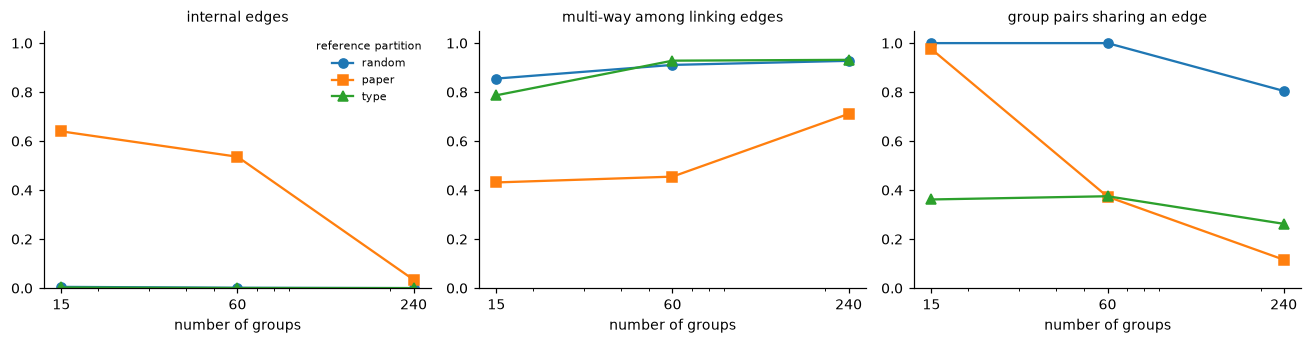

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col in zip(axes, ["internal edges", "multi-way among linking edges", "group pairs sharing an edge"]):
    for kind, mk in zip(["random", "paper", "type"], ["o", "s", "^"]):
        r = ref.loc[kind]
        ax.plot(r.index, r[col], marker=mk, label=kind)
    ax.set_xscale("log"); ax.set_xlabel("number of groups"); ax.set_title(col, fontsize=9); ax.set_ylim(0, 1.05)
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xticks(GROUPS, [str(b) for b in GROUPS])
axes[0].legend(frameon=False, fontsize=7, title="reference partition", title_fontsize=7)
fig.tight_layout()

In [20]:
# Do the section 5-7 findings depend on the 20% hub threshold?
rows = []
s26 = snapshot(tkh, max(cfg.cutoffs))
for share in (0.1, 0.2, 0.3, None):
    it, Bh, _, rel_h = st.concept_incidence(tkh, s26, max_paper_share=share)
    ip = [pap26[v] for v in it]
    inv = 1 / (Bh.sum(axis=0) - 1)
    r60 = pd.DataFrame([st.collapse_stats(st.reference_partition("paper", it, 60, tkh, s, s26), Bh) for s in range(10)]).mean()
    r15 = pd.DataFrame([st.collapse_stats(st.reference_partition("random", it, 15, tkh, s, s26), Bh) for s in range(10)]).mean()
    p15 = pd.DataFrame([st.collapse_stats(st.reference_partition("paper", it, 15, tkh, s, s26), Bh) for s in range(10)]).mean()
    rows.append({"hubs removed above": "none" if share is None else f"{share:.0%}", "edges": Bh.shape[1],
                 "evaluated_on share of inverse-size weight": inv[rel_h == "evaluated_on"].sum() / inv.sum(),
                 "paper-preserving @60: internal edges": r60["internal edges"],
                 "random @15: multi-way among linking edges": r15["multi-way among linking edges"],
                 "paper-preserving @15: group pairs sharing an edge": p15["group pairs sharing an edge"],
                 "paper-preserving @60: Spearman(presence, counts)": r60["Spearman(presence, counts), uniform weights"]})
pd.DataFrame(rows).set_index("hubs removed above")

,edges,evaluated_on share of inverse-size weight,paper-preserving @60: internal edges,random @15: multi-way among linking edges,paper-preserving @15: group pairs sharing an edge,"paper-preserving @60: Spearman(presence, counts)"
hubs removed above,,,,,,
10%,550,0.858,0.555,0.784,0.970,0.508
20%,554,0.853,0.534,0.856,0.978,0.509
30%,554,0.845,0.506,0.890,0.988,0.509
none,554,0.850,0.491,0.891,0.988,0.491


**Reading the reference partitions:**
- **Multi-way edges persist for every kind of partition and every level.** A large share of the edges that still link groups touch three or more of them. A pairwise summary would turn each into many pairs. So a coarser level must keep the *incidence* (which groups each fine edge touches), not a group-pair graph.
- **Whether edges become internal depends on what the groups keep together.**
  - Every edge is one paper's star. When groups hold whole papers, most edges fall inside one group, and the edges left to link groups are those containing a node shared with another paper.
  - Random or type-preserving groups internalise almost nothing.
  - So the more a coarsening keeps papers together, the faster its structural signal between groups thins out at coarse levels, down to the cross-paper bridges.
- **Edge presence stops discriminating as random or paper-preserving groups grow.**
  - Under random grouping every pair of groups shares an edge already at 60 groups. Under paper-preserving grouping the share rises steeply towards 15 groups.
  - Type-preserving groups stay sparse, because groups of different non-method types share an edge only through a method, apart from datasets and metrics (section 1).
  - Where presence saturates, a structural score must be normalised per level and must measure *how much* two groups share, not *whether* they share.
- **Presence and counts disagree, and how much depends on the weighting.**
  - Affinities from endpoint counts rank group pairs differently from presence-only ones.
  - The gap grows at coarse levels for random and type-preserving groups. Paper-preserving groups disagree most at 60 groups.
  - With every edge weighted equally, the gap is larger than with inverse-size weights.
  - Counts keep the multiplicity that presence throws away. Whether that helps is an outcome question.
- **Paper coverage saturates.** Coarse random groups touch most papers, so paper coverage can only serve as a hub signal for groups if it is compared with what random groups of the same size cover.
- **Robustness.** The sensitivity table re-runs one statistic for each finding: relation weight, internal edges, multi-way edges, saturation, and presence vs counts. Dropping hubs at 10%, 30% or not at all changes these numbers little and none of the conclusions. The other cells of the main table were not re-run.

## 8. What must stay out of the coarsening

The project's evaluation scores coherence by **citation coupling** (E1a, `tkh/evaluate/coherence.py`) and judges labels from **claims and titles** (E3). Neither can be used to build the clusters, or the evaluation becomes circular. The question here is where these signals *leak* into structure a coarsening would plausibly use, and which part of the evaluation remains a clean test.

In [21]:
ov = st.cited_work_name_overlap(tkh)
pk = defaultdict(set)
for v, ps in papers.items():
    if ntype[v] in CONCEPT_TYPES:
        for kk in st.name_keys(tkh, v):
            for a in ps:
                pk[a].add(kk)
presented = {a: m[1] for m, r, a in zip(E["members"], E["relation_type"], E["article_id"]) if r == "presents"}
bykey = defaultdict(set)
for a, v in presented.items():
    for kk in st.name_keys(tkh, v):
        bykey[kk].add(a)
survive = set()
for m, r, a in zip(E["members"], E["relation_type"], E["article_id"]):
    if r == "cites":
        for wk in m[1:]:
            ks = st.name_keys(tkh, wk)
            if not (ks & pk[a]):
                survive |= {(a, b) for kk in ks for b in bykey.get(kk, ()) if b != a}
pd.Series({
    "cited works (distinct)": ov["cited works"],
    "cited works named like some concept node": ov["named like some concept node"],
    "citation incidences": ov["citation incidences"],
    "citation incidences named like a concept of the citing paper (removed by E1a's filter)": ov["named like a concept of the citing paper"],
    "direct-citation pairs (cited work = other paper's presented method)": len(direct_set),
    "lineage pairs (extends -> presents)": len(lineage),
    "lineage pairs that are also direct citations": sum((a, b) in direct_set for a, b in lineage),
    "direct-citation pairs surviving the filter": len(survive),
    "lineage pairs among them (0 by construction, see below)": len(set(lineage) & survive)}, name="count").to_frame()

,count
cited works (distinct),580
cited works named like some concept node,233
citation incidences,878
citation incidences named like a concept of the citing paper (removed by E1a's filter),260
direct-citation pairs (cited work = other paper's presented method),90
lineage pairs (extends -> presents),49
lineage pairs that are also direct citations,30
direct-citation pairs surviving the filter,41
"lineage pairs among them (0 by construction, see below)",0


In [22]:
# claims edges: whose methods they hold, whether they change the hub sets, and which concept-view pairs depend on them
from dataclasses import replace
presented_m = {a: m[1] for m, r, a in zip(E["members"], E["relation_type"], E["article_id"]) if r == "presents"}
slots = [(v, a) for m, r, a in zip(E["members"], E["relation_type"], E["article_id"]) if r == "claims" for v in m if ntype[v] == "method"]
no_claims = replace(tkh, edges=E[E["relation_type"] != "claims"])
same_hubs = all(st.concept_components(tkh, snapshot(tkh, c), max_paper_share=HUB)[2] ==
                st.concept_components(no_claims, snapshot(no_claims, c), max_paper_share=HUB)[2] for c in cfg.cutoffs)
pairs_by_link = spec.groupby("link").apply(lambda g: set(zip(g["earlier"], g["later"])))
claims_pairs = pairs_by_link.get("claims ~ extends", set())
other = set().union(*(v for k, v in pairs_by_link.items() if k != "claims ~ extends"))
print(f"method slots in claims edges: {len(slots)}, of which the paper's own presented method: {sum(presented_m.get(a) == v for v, a in slots)}")
print(f"hub sets identical with and without claims edges at every snapshot: {same_hubs}")
print(f"concept-view pairs linked through claims: {len(claims_pairs)}, of which linked only through claims: {len(claims_pairs - other)}")

method slots in claims edges: 478, of which the paper's own presented method: 442
hub sets identical with and without claims edges at every snapshot: True
concept-view pairs linked through claims: 8, of which linked only through claims: 1


In [23]:
# citation coupling with the residual filter, computed in tkh/structure.py (same definition as the E1a ruler)
P, Cc, _ = st.citation_coupling(tkh, snapshot(tkh, max(cfg.cutoffs)))
iu = np.triu_indices(len(P), 1)
c = Cc[iu]
overlap = np.array([C_mat.loc[P[i], P[j]] > 0 for i, j in zip(*iu)])   # pairs sharing a non-hub concept node
print(f"{len(P)} citing papers, {len(c)} pairs")
pd.DataFrame({s: {"pairs": int(mk.sum()), "share of pairs": mk.mean(), "P(coupled)": (c[mk] > 0).mean(),
                  "mean coupling": c[mk].mean(), "share of coupling mass": c[mk].sum() / c.sum()}
              for s, mk in [("overlap (share a non-hub concept)", overlap), ("no overlap", ~overlap)]}).T

37 citing papers, 666 pairs


,pairs,share of pairs,P(coupled),mean coupling,share of coupling mass
overlap (share a non-hub concept),283.0,0.425,0.470,0.023,0.649
no overlap,383.0,0.575,0.245,0.009,0.351


**Leakage paths and what they mean for the evaluation:**
- **Concept structure re-encodes part of the citation signal.** Many cited works carry the name of a concept node, typically a method a paper extends or uses and also cites. Most lineage links are also direct citations. Clustering on `extends` is legitimate structure, but a citation ruler then partly re-measures it.
- **E1a's residual filter removes the most direct copy.** It drops every citation whose cited work is named like a concept of the citing paper. It removes *all* lineage-coinciding citations, but that is true by construction: the extending paper's `extends` edge contains the cited method, so the name is among its concepts. The count shows what the filter does, not that it works.
- **The filter alone does not make the ruler independent of structure.**
  - The "overlap" stratum is exactly the concept view's linked pairs; the project's E1a ruler uses the same split.
  - Residual coupling is about twice as likely inside it, and holds most of the coupling mass.
  - The overlap and pooled lifts are therefore partly self-confirming: papers that share concepts also share references.
  - **The no-overlap stratum is the cleanest available test.** There, two papers share no non-hub concept that could explain their coupling, and only the clustering can have grouped their concepts.
  - It is still not perfectly clean. Such papers can share hubs, be connected over several hops, or have similar names, and they inherit period effects: even the year-matched null of section 4 sits above independence.
  - E1a reports this stratum separately. It should be read as the primary evidence.
- **`cites` edges and `cited_work` nodes, names included,** must stay out of the hypergraph a coarsening uses, and out of any name-based signal.
- **Claims, future topics and titles** carry no cross-paper structure (section 1), and their text is the E3 judge's evidence. They stay out of the clustering.
  - Claims edges do hold concept nodes (methods), almost always the paper's own presented method. Counting them changes no hub set in this export (check above).
  - Claims create a handful of concept-view pairs (`claims ~ extends`, section 3), and only one of them is linked through nothing else. Ignoring claims edges loses almost nothing.
- **Authors** are only weakly associated with the concept view (section 4). Kept out of the clustering, co-authorship remains a possible second ruler, but a weak one: it links few pairs and reflects social rather than topical proximity.

## 9. Conclusions: what a coarsening algorithm should use, carry and leave out

**(A) Finest-level signals for forming super-nodes**

*Supported by the evidence here:*
1. **The six method-centred relations as hyper-edges, restricted to concept nodes.**
   - They are the only structure most concept nodes have, and they group a paper's members *by role*: its tasks, techniques, benchmark datasets and metrics (sections 1 and 5).
   - Their multi-way form matters. Five of the six relations are large stars, with median arity 10–17. `evaluated_on` is many small triples, and makes up half of the edges. A pairwise projection changes which relation dominates (section 5).
2. **Cross-paper bridges are the only structural evidence that nodes of different papers belong together.** They are few and carried mainly by `extends` (shared methods, and lineage), `addresses` (shared tasks) and `evaluated_on` (shared benchmarks) (sections 3 and 5). Components and problems recur almost never, so their relations carry within-paper grouping only.
3. **Widely shared nodes must be down-weighted.** They make almost all papers look linked (section 2).
   - Any hard threshold sits inside a long tail, so it is a choice.
   - The hub set churns between snapshots (section 6). A soft weight by paper share, or a hub list fixed across snapshots, is more stable than a per-snapshot hard threshold.
4. **The edge weighting must be chosen deliberately.** It decides which relation drives the grouping. Inverse-size weighting hands most of the weight to the small `evaluated_on` edges; a pairwise projection hands it to the large task and technique stars (section 5). Because each relation has essentially one member type, a relation weighting is also a weighting of node types (section 1).
5. **Cluster on concept nodes, and attach the rest.**
   - Claims, future topics and article nodes carry no cross-paper structure (section 1).
   - Authors and cited works do, but must stay out (C).
   - So non-concept nodes cannot be placed by structure and need a placement rule rather than a clustering signal. The data offer a natural attachment point per paper: its presented method, on which every method-centred star is centred and which most claims mention.

*Hypotheses this notebook motivates but does not test:*
- **Relation-typed weights,** in particular a higher weight for lineage, and a relation-balanced weighting.
- **Test:** compare such weightings, and drop-one-relation variants, on held-out evidence: the no-overlap stratum of citation coupling, ground-truth co-membership, or a retrieval task.

**(B) Structure to carry over to each coarser level**

*Supported by section 7 (reference partitions, independent of any algorithm):*
1. **The collapsed incidence:** for every fine hyper-edge, the groups it touches. Multi-way edges persist at every level under every reference partition, so a group-pair graph would lose structure.
2. **Endpoint counts per group and edge.** Count-based and presence-based affinities rank group pairs differently, by an amount that depends on the weighting. The gap grows at coarse levels for random and type-preserving groups, and peaks at intermediate levels for paper-preserving ones. An algorithm that drops counts discards information exactly where it diverges most.
3. **A graded, per-level-normalised affinity.** Under random and paper-preserving grouping, edge presence saturates as groups grow, so "whether two groups share an edge" stops discriminating.
4. **The relation type and the paper of each edge.**
   - The relation type is needed for any relation or type weighting (A4).
   - The paper and year are needed to recognise lineage, which is directed and dated (section 3), and to follow hub churn and attachment over time (section 6).

*Hypotheses, not tested here:*
- **Internal-edge totals per group**, i.e. the structure a group has absorbed, as input to a size or density normaliser.
- **Paper coverage as a coarse hub signal**, relative to random groups of the same size; raw coverage saturates (section 7).
- **Test for both:** compare variants on held-out coherence (the no-overlap citation stratum, ground-truth co-membership) and on a retrieval task.

**(C) Structure to leave out of the coarsening, so that coherence can be evaluated independently**
1. **`cites` edges and `cited_work` nodes, including their names.** They are the citation ruler.
   - Concept structure partly coincides with citations. Most lineage links are also direct citations (section 3), and papers that share a non-hub concept are about twice as likely to be citation-coupled (section 8). The evaluation therefore needs a residual filter, which drops citations named like a concept of the citing paper.
   - Even so, only the **no-overlap stratum** (paper pairs sharing no non-hub concept) is a test where shared structure cannot explain the coupling (section 8). It should be read as the primary coherence evidence.
2. **Claims, future topics and article titles.** They carry no cross-paper structure, and their text is the label judge's held-out evidence. Ignoring claims edges loses almost nothing: one paper pair in this export (section 8).
3. **Authors.** They are weakly tied to the concept view. Left out, co-authorship remains available as a weak second ruler.
4. **Ground truth**, which is not part of the graph.